In [162]:
#harmonic oscillator d^2x / dt^2 = - w^2 * x

import matplotlib.pyplot as plt
import matplotlib.pyplot as plt1

w = 1

def f(x, v):
    return v, - w * w * x

PLOT FOR X(T) and V(T):


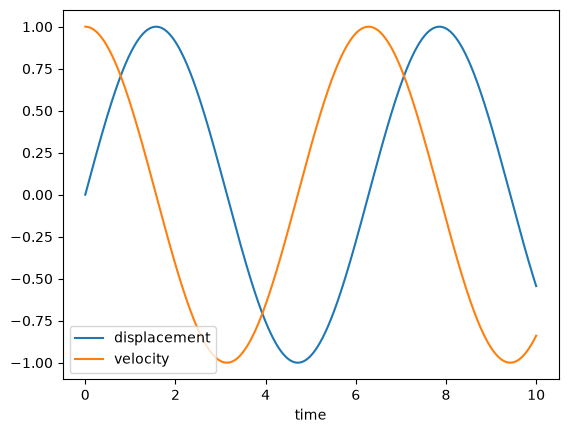

PLOT FOR X VS V:


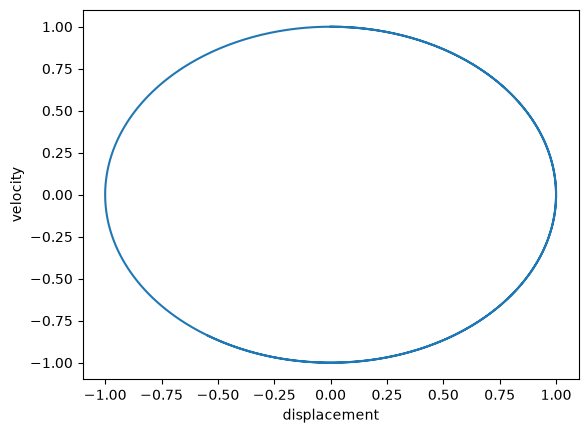

In [166]:
#using rk4 method

t0 = 0
tmax = 10

#set time-step
h = 0.01

#set initial conditions
x0 = 0
v0 = 1

time = [t0]
displacement = [x0]
velocity = [v0]

while t0 < tmax - 1e-12:
    k1x, k1v = f(x0, v0)
    k2x, k2v = f(x0 + h/2*k1x, v0 + h/2*k1v)
    k3x, k3v = f(x0 + h/2*k2x, v0 + h/2*k2v)
    k4x, k4v = f(x0 + h*k3x, v0 + h*k3v)    
    v0 = v0 + h * (k1v + 2 * k2v + 2 * k3v + k4v) / 6  
    x0 = x0 + h * (k1x + 2 * k2x + 2 * k3x + k4x) / 6

    
    t0 = t0 + h

    time.append(t0)
    displacement.append(x0)
    velocity.append(v0)

print("PLOT FOR X(T) and V(T):")
plt.plot(time, displacement)
plt.plot(time, velocity)
plt.xlabel("time")
plt.legend(["displacement", "velocity"])
plt.show()

print("PLOT FOR X VS V:")
plt1.plot(displacement, velocity)
plt1.xlabel("displacement")
plt1.ylabel("velocity")
plt1.show()

In [167]:
#Energy conservation in different numerical integrators: Euler, Midpoint, RK4

#Euler
t0 = 0

#set initial conditions
x0 = 0
v0 = 1

displacement_euler = [x0]
velocity_euler = [v0]

while t0 < tmax - 1e-12:
    v0 = v0 + h * v(x0)
    x0 = x0 + h * x(v0)
    t0 = t0 + h

    displacement_euler.append(x0)
    velocity_euler.append(v0)

#Midpoint
t0 = 0

#set initial conditions
x0 = 0
v0 = 1

displacement_midpoint = [x0]
velocity_midpoint = [v0]

while t0 < tmax - 1e-12:
    k1x, k1v = f(x0, v0)
    k2x, k2v = f(x0 + h/2*k1x, v0 + h/2*k1v)
    v0 = v0 + h * k2v
    x0 = x0 + h * k2x
    t0 = t0 + h

    displacement_midpoint.append(x0)
    velocity_midpoint.append(v0)

In [168]:
#Energy calculation

#define k and m
k = 1
m = 1

def E(x, v):
    return 1 / 2 * m * v**2 + 1 / 2 * k * x**2

energy_rk = []
energy_euler = []
energy_midpoint = []

for i in range(0, len(time)):
    energy_rk.append(E(displacement[i], velocity[i]))
    energy_euler.append(E(displacement_euler[i], velocity_euler[i]))
    energy_midpoint.append(E(displacement_midpoint[i], velocity_midpoint[i]))

for n in [0, 2, 5, 10, 50, 100, 200, 500, 1000]:
    print(f"{n}th energy")
    print("Euler: ", f"{abs(energy_euler[n] - energy_euler[0]) / energy_euler[0] * 100}%")
    print("Midpoint: ", f"{abs(energy_midpoint[n] - energy_midpoint[0]) / energy_midpoint[0] * 100}%")
    print("RK4: ", f"{abs(energy_rk[n] - energy_rk[0]) / energy_rk[0] * 100}%")
    print("=" * 60)

0th energy
Euler:  0.0%
Midpoint:  0.0%
RK4:  0.0%
2th energy
Euler:  0.019997000100002715%
Midpoint:  4.999999969612645e-07%
RK4:  2.7644553313166398e-12%
5th energy
Euler:  0.04993002959448045%
Midpoint:  1.2500000146076218e-06%
RK4:  6.938893903907228e-12%
10th energy
Euler:  0.09938615069005063%
Midpoint:  2.500000051419704e-06%
RK4:  1.389999226830696e-11%
50th energy
Euler:  0.42189115908191077%
Midpoint:  1.2500000812210033e-05%
RK4:  6.935563234833353e-11%
100th energy
Euler:  0.4581931371733017%
Midpoint:  2.5000003112118918e-05%
RK4:  1.3876677584789832e-10%
200th energy
Euler:  0.3742772439925379%
Midpoint:  5.000001255250908e-05%
RK4:  2.776334717680129e-10%
500th energy
Euler:  0.2674336993815474%
Midpoint:  0.00012500007837701332%
RK4:  6.942668662190954e-10%
1000th energy
Euler:  0.45797535566520775%
Midpoint:  0.00025000031265154377%
RK4:  1.388811288194347e-09%
